# Pulsed excitation and TCSPC

TCSPC records photon delays relative to the most recent excitation pulse.
We first recover the lifetime of a simple two-state emitter, then shorten
the pulse interval and introduce a transfer partner. This separates an
observed pulse delay from a molecule's actual time spent in S1.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fluopy import analysis as an
from fluopy import emissions as em
from fluopy import fluo_data as fd
from fluopy import fluorophores as fl
from fluopy import transitions as tr

## A two-state emitter with a known lifetime

The kinetic rates are illustrative: S1 decays only by fluorescence with a
3 ns lifetime. The bundled Cy5 data provide its spectrum for detection.

Pulse excitation is set by excitation_rates in the tcspc() call. Each entry
specifies a fluorophore name and its excitation rate during a pulse, in 1/s.
For a molecule in S0, the probability of excitation by one pulse is

$$P_\mathrm{exc} = 1 - \exp(-k_\mathrm{exc} \, t_\mathrm{pulse}).$$

Here an excitation rate of 1e10 /s and a pulse duration of 1e-10 s give a
probability of approximately 0.63 per pulse. The repetition interval controls
how often these pulses occur.

When excitation_rates is supplied, the numerical excitation rates in the
TransitionSet are overridden. We retain an S0-to-S1 record with rate zero so
that detailed trajectories can identify the excitation events, using
keep_zero_rates=True to preserve it. This record does not set the pulse strength.

If excitation_rates is omitted, Fluopy instead interprets the model's excitation
rates as averages over a full pulse interval and multiplies them by
time_between_pulses / pulse_duration to obtain the rates during a pulse.

In [2]:
lifetime = 3e-9
dye = fl.Fluorophore("dye", [0, 0], constants=fd.cy5_dna)
system = fl.FluorophoreSystem([dye])
model = tr.TransitionSet(
    {
        "dye": [
            tr.Transition(tr.TransitionType.EXCITATION, 0, [0]),
            tr.Transition(tr.TransitionType.FLUORESCENT_EMISSION, 1 / lifetime, [0]),
        ]
    },
    system,
    keep_zero_rates=True,
)
channels = {
    "left": em.DetectionChannel(routing_probability=0.5),
    "right": em.DetectionChannel(routing_probability=0.5),
}

## Collect delays in named channels

pulse_duration sets the excitation probability through the expression above;
the pulse is otherwise treated as instantaneous. With a 50 ns repetition
interval, the 3 ns decay is well resolved before the next pulse.

The two detector channels share photons through an ideal 50/50 splitter.
We first inspect their photon counts and mean delays, then compare their
delay distributions with the expected exponential decay.

In [3]:
acquisition = em.Emissions(frame_time="50us", channels=channels, seed=41)
_, _, delays, _ = acquisition.tcspc(
    model,
    number_pulses=20_000,
    pulse_duration=1e-10,
    time_between_pulses=50e-9,
    excitation_rates={"dye": 1e10},
    size=10_000,
    store_time_points=True,
    details=False,
)
pd.DataFrame(
    {
        "photons": {name: values.size for name, values in delays.items()},
        "mean pulse delay (ns)": {
            name: values.mean() * 1e9 for name, values in delays.items()
        },
    }
)

,photons,mean pulse delay (ns)
left,6349,3.001776
right,6374,3.049202


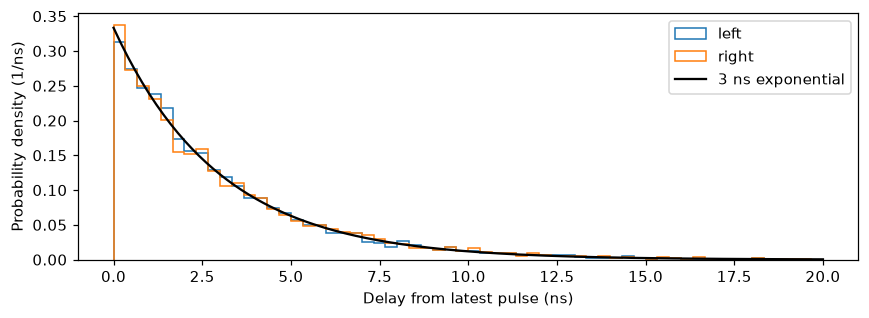

In [4]:
fig, ax = plt.subplots(figsize=(8, 3))
bins = np.linspace(0, 20, 61)
for name, values in delays.items():
    ax.hist(values * 1e9, bins=bins, density=True, histtype="step", label=name)
time_ns = np.linspace(0, 20, 200)
ax.plot(time_ns, np.exp(-time_ns / 3) / 3, color="black", label="3 ns exponential")
ax.set(xlabel="Delay from latest pulse (ns)", ylabel="Probability density (1/ns)")
ax.legend()
fig.tight_layout()

The channel histograms estimate the same decay, with counting noise from
routing photons to different detectors.

## A pulse interval shorter than the lifetime

With a 2 ns interval, a photon can arrive after a later pulse than the one
that excited the molecule. Reported delays are measured from that latest
pulse, so their average is shorter than the intrinsic 3 ns lifetime.

Set details=True to also retain each fluorophore's complete simulated state
path and the times and identities of all transitions, including excitations and
non-emitting events. This gives access to S1 entry and exit times even when a
photon is not detected. Keeping those trajectories requires additional memory.
We use this detailed path below to measure how long the molecule actually
remained excited.

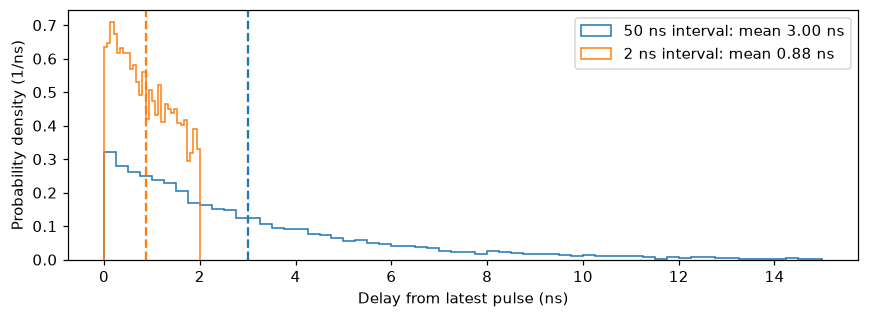

In [5]:
short_acquisition = em.Emissions(frame_time="10us", channels=channels, seed=42)
_, _, short_delays, short_simulation = short_acquisition.tcspc(
    model,
    number_pulses=30_000,
    pulse_duration=1e-10,
    time_between_pulses=2e-9,
    excitation_rates={"dye": 1e10},
    size=10_000,
    details=True,
)
long_mean_ns = delays["left"].mean() * 1e9
short_mean_ns = short_delays["left"].mean() * 1e9
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(
    delays["left"] * 1e9,
    bins=np.linspace(0, 15, 61),
    density=True,
    histtype="step",
    color="C0",
    label=f"50 ns interval: mean {long_mean_ns:.2f} ns",
)
ax.hist(
    short_delays["left"] * 1e9,
    bins=np.linspace(0, 2, 31),
    density=True,
    histtype="step",
    color="C1",
    label=f"2 ns interval: mean {short_mean_ns:.2f} ns",
)
ax.axvline(long_mean_ns, color="C0", linestyle="--")
ax.axvline(short_mean_ns, color="C1", linestyle="--")
ax.set(xlabel="Delay from latest pulse (ns)", ylabel="Probability density (1/ns)")
ax.legend()
fig.tight_layout()

## Recover the actual S1 residence times

Analysis uses the state path in short_simulation to collect the completed S1
residence intervals. A molecule that remains excited across several pulses
still has one continuous S1 residence. Subsequent pulses do not reset that
residence time.

The comparison below uses the same 2 ns acquisition: the photon delays are
measured from the latest pulse, while the residence times run from actual
excitation to de-excitation. Analysis includes all completed S1 visits, including
ones whose photon was not detected; the final incomplete visit is excluded.

In [6]:
short_analysis = an.Analysis(short_simulation)
s1_residences = short_analysis.get_fluorescence_lifetimes("dye")
residence_mean_ns = s1_residences.mean() * 1e9
pd.Series(
    {
        "mean detected delay from latest pulse (ns)": short_mean_ns,
        "mean completed S1 residence (ns)": residence_mean_ns,
        "intrinsic lifetime specified in model (ns)": lifetime * 1e9,
    }
)

mean detected delay from latest pulse (ns)    0.881349
mean completed S1 residence (ns)              2.979337
intrinsic lifetime specified in model (ns)    3.000000
dtype: float64

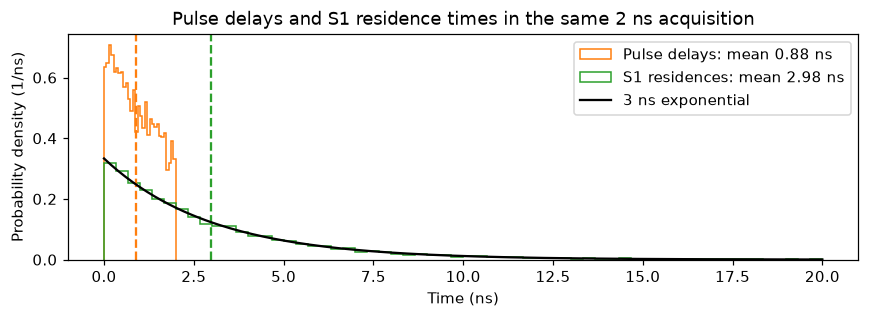

In [7]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(
    short_delays["left"] * 1e9,
    bins=np.linspace(0, 2, 31),
    density=True,
    histtype="step",
    color="C1",
    label=f"Pulse delays: mean {short_mean_ns:.2f} ns",
)
ax.hist(
    s1_residences * 1e9,
    bins=bins,
    density=True,
    histtype="step",
    color="C2",
    label=f"S1 residences: mean {residence_mean_ns:.2f} ns",
)
ax.axvline(short_mean_ns, color="C1", linestyle="--")
ax.axvline(residence_mean_ns, color="C2", linestyle="--")
ax.plot(time_ns, np.exp(-time_ns / 3) / 3, color="black", label="3 ns exponential")
ax.set(
    xlabel="Time (ns)",
    ylabel="Probability density (1/ns)",
    title="Pulse delays and S1 residence times in the same 2 ns acquisition",
)
ax.legend()
fig.tight_layout()

## Add a transfer partner

The donor has the same 3 ns decay. A supplied FRET rate of 1e8 /s adds a
competing channel while the acceptor is in S0. Only the donor is directly
excited. This example uses an ideal emitter-selected collection path to
isolate donor photons; ordinary spectral detection should instead use
bandpasses with fluorophore_ids left unset.

In [8]:
pair_system = fl.FluorophoreSystem(
    [
        fl.Fluorophore("donor", [0, 0], constants=fd.atto643),
        fl.Fluorophore("acceptor", [6, 0], constants=fd.cy5_dna),
    ]
)
pair_model = tr.TransitionSet(
    {
        "donor": [
            tr.Transition(tr.TransitionType.EXCITATION, 0, [0]),
            tr.Transition(tr.TransitionType.FLUORESCENT_EMISSION, 1 / lifetime, [0]),
        ],
        "acceptor": [
            tr.Transition(tr.TransitionType.EXCITATION, 0, [1]),
            tr.Transition(tr.TransitionType.FLUORESCENT_EMISSION, 1 / 4e-9, [1]),
        ],
        "D: donor, A: acceptor, dist: 6.0": [
            tr.Transition(tr.TransitionType.FRET, 1e8, [(0, 1)]),
        ],
    },
    pair_system,
    keep_zero_rates=True,
)
donor_photons = em.Emissions(
    frame_time="50us",
    channels={"donor_only": em.DetectionChannel(fluorophore_ids=frozenset({0}))},
    seed=43,
)
available, unavailable, transfer_delays, _ = donor_photons.tcspc(
    pair_model,
    number_pulses=20_000,
    pulse_duration=1e-10,
    time_between_pulses=100e-9,
    excitation_rates={"donor": 1e10, "acceptor": 0},
    size=10_000,
)
pd.Series(
    {
        "mean donor delay without partner (ns)": delays["left"].mean() * 1e9,
        "mean donor delay with partner (ns)": transfer_delays["donor_only"].mean()
        * 1e9,
        "expected residence with available partner (ns)": 1e9 / (1 / lifetime + 1e8),
    }
)

mean donor delay without partner (ns)             3.001776
mean donor delay with partner (ns)                2.290468
expected residence with available partner (ns)    2.307692
dtype: float64

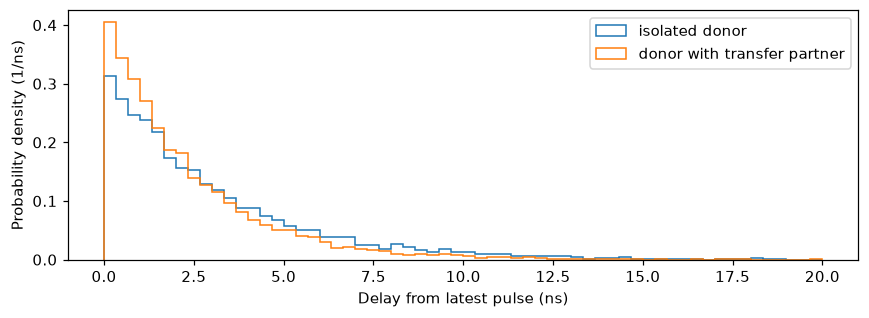

In [9]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(
    delays["left"] * 1e9,
    bins=bins,
    density=True,
    histtype="step",
    label="isolated donor",
)
ax.hist(
    transfer_delays["donor_only"] * 1e9,
    bins=bins,
    density=True,
    histtype="step",
    label="donor with transfer partner",
)
ax.set(xlabel="Delay from latest pulse (ns)", ylabel="Probability density (1/ns)")
ax.legend()
fig.tight_layout()

The long pulse interval and fast acceptor recovery make the partner available
at most donor excitations in this example. In a more complex system its
availability changes, so the delay distribution can mix different conditions.

The paired/unpaired return arrays classify whether a positive-rate paired
transition was available immediately before emission, with the emitter as
its first, active component. They do not classify whether transfer actually
occurred earlier. This convention applies to any paired mechanism, not just
FRET. Light-driven processes other than S0 excitation retain their supplied
rates during tcspc(); those rates should correspond to the mean irradiance.

See [Interpreting events and statistics](../../source/model_conventions.rst)
for further conventions, and [Extending Fluopy](Tutorial_extending_fluopy.ipynb)
for custom processes and spectra.